# Producción y valor de los campos petroleros de Noruega
**Pregunta de negocio:** ¿cómo evoluciona la producción de petróleo de la plataforma continental noruega, qué campos maduros sostienen el valor remanente y cuánto vale su producción futura según el precio del Brent?

**Datos:** datos oficiales y abiertos de Sodir (producción mensual por campo desde 1971 y reservas) y precio mensual del Brent (FRED). Ver `datos/FUENTES.md`.

**Herramientas:** Python, pandas, numpy y matplotlib. Las funciones están en `petro.py`.

## 1. Cargar y limpiar
`petro.py` renombra las columnas, convierte metros cúbicos estándar a barriles (1 Sm³ = 6,2898 bbl), pasa los volúmenes mensuales a **miles de barriles por día (kbd)** y calcula el **corte de agua**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import petro as P

prod = P.cargar_produccion()
reservas = P.cargar_reservas()
campos = P.cargar_campos()
brent = P.cargar_brent()
ULTIMO = prod['fecha'].max()
print('Datos hasta:', ULTIMO.strftime('%m/%Y'), '| campos:', prod['campo'].nunique(), '| filas:', len(prod))
prod[['campo', 'fecha', 'petroleo_kbd', 'agua_kbd', 'corte_agua']].tail()

Datos hasta: 07/2026 | campos: 136 | filas: 28455


,campo,fecha,petroleo_kbd,agua_kbd,corte_agua
28450,ØST FRIGG,1997-09-01,0.0,0.0,NaN
28451,ØST FRIGG,1997-10-01,0.0,0.0,NaN
28452,ØST FRIGG,1997-11-01,0.0,0.0,NaN
28453,ØST FRIGG,1997-12-01,0.0,0.0,NaN
28454,ØST FRIGG,1998-01-01,0.0,0.0,NaN


## 2. Revisar calidad
Vacíos, duplicados (un campo no puede tener dos registros del mismo mes) y valores negativos. Los negativos son correcciones que Sodir publica sobre meses anteriores: se conservan en los totales y la curva de declinación los ignora.

In [2]:
print('Vacíos:', int(prod[['petroleo_msm3', 'gas_bsm3', 'agua_msm3']].isna().sum().sum()))
print('Duplicados campo-mes:', int(prod.duplicated(['campo', 'fecha']).sum()))
print('Valores negativos:', int((prod[['petroleo_msm3', 'gas_bsm3', 'agua_msm3']] < 0).sum().sum()))
print('Campos con reservas oficiales:', reservas['campo'].isin(prod['campo']).sum(), 'de', prod['campo'].nunique())

Vacíos: 0
Duplicados campo-mes: 0
Valores negativos: 115
Campos con reservas oficiales: 133 de 136


## 3. La producción del país: pico, caída y recuperación

Pico: 2001 con 3,117 kbd
Mínimo después del pico: 2019 con 1,410 kbd (-55%)
Promedio 2026 (ene–07): 1,878 kbd


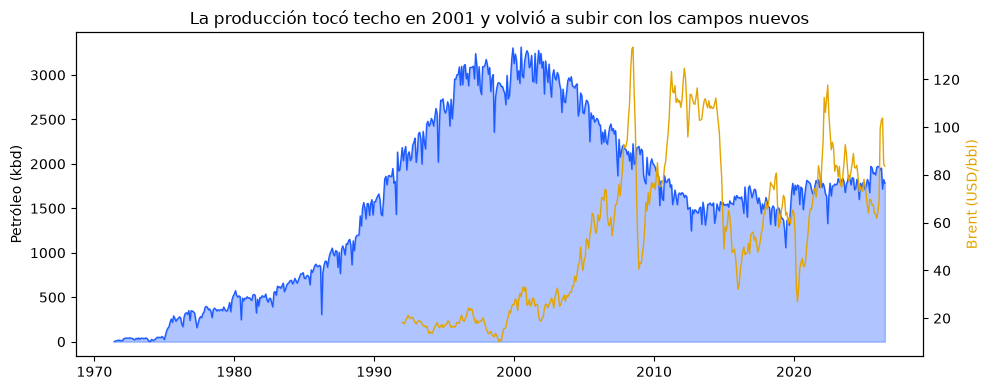

In [3]:
nac = prod.groupby('fecha').agg(petroleo=('petroleo_kbd', 'sum'), agua=('agua_kbd', 'sum'))
anual = nac['petroleo'].groupby(nac.index.year).mean()
pico = anual.idxmax()
print(f'Pico: {pico} con {anual[pico]:,.0f} kbd')
print(f'Mínimo después del pico: {anual.loc[pico:].idxmin()} con {anual.loc[pico:].min():,.0f} kbd '
      f'({anual.loc[pico:].min() / anual[pico] - 1:.0%})')
print(f'Promedio 2026 (ene–{ULTIMO:%m}): {anual[ULTIMO.year]:,.0f} kbd')

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(nac.index, nac['petroleo'], color='#1E5BFF', alpha=.35)
ax.plot(nac.index, nac['petroleo'], color='#1E5BFF', lw=1)
ax2 = ax.twinx(); b = brent.set_index('fecha')['brent']; ax2.plot(b.index, b, color='#E3A400', lw=1)
ax.set_ylabel('Petróleo (kbd)'); ax2.set_ylabel('Brent (USD/bbl)', color='#E3A400')
ax.set_title('La producción tocó techo en 2001 y volvió a subir con los campos nuevos')
plt.tight_layout(); plt.savefig('graficos/produccion_nacional.png', dpi=120); plt.show()

## 4. ¿Qué campos producen hoy? Concentración del riesgo

Producción media últimos 12 meses: 1,905 kbd en 94 campos
El campo principal aporta 34%; los 2 primeros, 44%; los 10 primeros, 65%


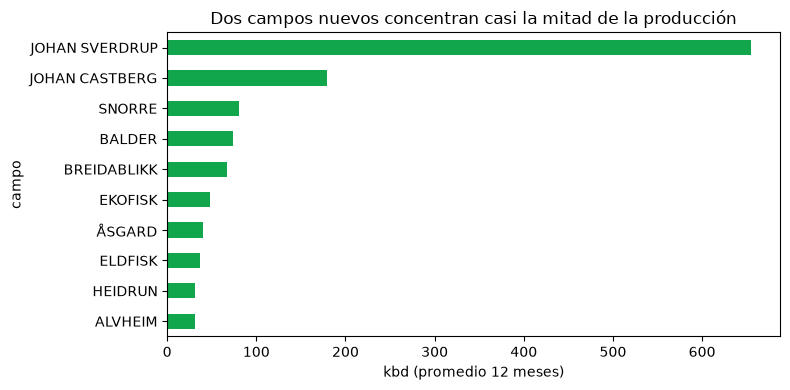

campo
JOHAN SVERDRUP    654.6
JOHAN CASTBERG    179.6
SNORRE             80.9
BALDER             74.4
BREIDABLIKK        67.5
EKOFISK            47.6
ÅSGARD             40.8
ELDFISK            37.0
HEIDRUN            31.7
ALVHEIM            31.3
Name: petroleo_kbd, dtype: float64

In [4]:
u12 = prod[prod['fecha'] > ULTIMO - pd.DateOffset(months=12)]
hoy = u12.groupby('campo')['petroleo_kbd'].mean().sort_values(ascending=False)
part = hoy / hoy.sum()
print(f'Producción media últimos 12 meses: {hoy.sum():,.0f} kbd en {(hoy > 0).sum()} campos')
print(f'El campo principal aporta {part.iloc[0]:.0%}; los 2 primeros, {part.iloc[:2].sum():.0%}; los 10 primeros, {part.iloc[:10].sum():.0%}')
ax = hoy.head(10).sort_values().plot(kind='barh', color='#11A64B', figsize=(8, 4),
    title='Dos campos nuevos concentran casi la mitad de la producción')
ax.set_xlabel('kbd (promedio 12 meses)'); plt.tight_layout(); plt.savefig('graficos/top_campos.png', dpi=120); plt.show()
hoy.head(10).round(1)

## 5. Madurez: el agua producida
El **corte de agua** es la fracción de agua en el líquido producido. Cuanto más alto, más madura la cuenca y más caro producir cada barril.

fecha
1990     0%
2000    39%
2010    61%
2020    63%
2026    61%
dtype: str
Hoy, por cada barril de petróleo salen 1.6 barriles de agua


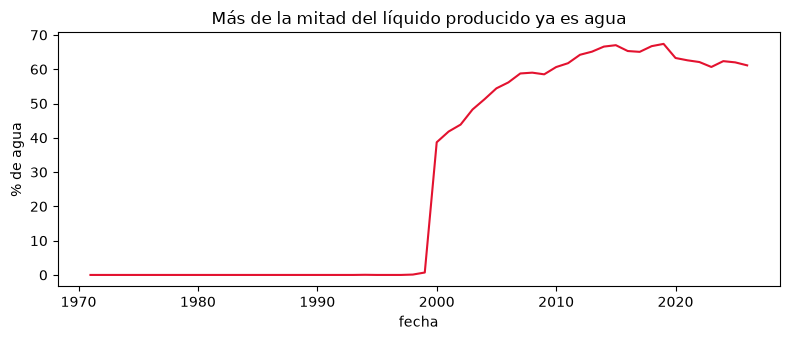

In [5]:
corte = (nac['agua'] / (nac['agua'] + nac['petroleo'])).groupby(nac.index.year).mean()
print(corte.loc[[1990, 2000, 2010, 2020, ULTIMO.year]].map('{:.0%}'.format))
agua_por_bbl = corte[ULTIMO.year] / (1 - corte[ULTIMO.year])
print(f'Hoy, por cada barril de petróleo salen {agua_por_bbl:.1f} barriles de agua')
ax = (corte * 100).plot(color='#E3122F', figsize=(8, 3.5), title='Más de la mitad del líquido producido ya es agua')
ax.set_ylabel('% de agua'); plt.tight_layout(); plt.savefig('graficos/corte_agua.png', dpi=120); plt.show()

## 6. Reservas: ¿dónde queda el petróleo?
Factor de avance = producido / recuperable total (estimación oficial).

In [6]:
tabla = (reservas.merge(campos, on='campo', how='left')
         .assign(avance=lambda d: 1 - d['remanente_mmbbl'] / d['recuperable_mmbbl'])
         .query('recuperable_mmbbl > 0')
         .sort_values('remanente_mmbbl', ascending=False))
total_rem = tabla['remanente_mmbbl'].sum()
print(f'Reservas remanentes de petróleo: {total_rem:,.0f} millones de barriles (MMbbl)')
print(f'A {brent.tail(12)["brent"].mean():.0f} USD/bbl (Brent 12 meses) eso equivale a ~{total_rem * brent.tail(12)["brent"].mean() / 1000:,.0f} mil millones de USD de ingreso bruto')
tabla[['campo', 'operador', 'estado', 'recuperable_mmbbl', 'remanente_mmbbl', 'avance']].head(10).round(2)

Reservas remanentes de petróleo: 5,153 millones de barriles (MMbbl)
A 78 USD/bbl (Brent 12 meses) eso equivale a ~401 mil millones de USD de ingreso bruto


,campo,operador,estado,recuperable_mmbbl,remanente_mmbbl,avance
109,JOHAN SVERDRUP,Equinor Energy AS,Producing,2531.02,1213.30,0.52
108,JOHAN CASTBERG,Equinor Energy AS,Producing,600.17,558.79,0.07
47,SNORRE,Equinor Energy AS,Producing,1988.52,402.61,0.80
12,HUGIN,Aker BP ASA,Approved for production,225.11,225.11,0.00
125,BALDER,Vår Energi ASA,Producing,706.66,204.67,0.71
96,HEIDRUN,Equinor Energy AS,Producing,1296.45,170.45,0.87
42,VALHALL,Aker BP ASA,Producing,983.91,162.78,0.83
137,BREIDABLIKK,Equinor Energy AS,Producing,210.21,159.26,0.24
128,ELDFISK,ConocoPhillips Skandinavia AS,Producing,969.70,146.99,0.85
121,MUNIN,Aker BP ASA,Approved for production,121.02,121.02,0.00


## 7. Curvas de declinación (Arps)
Para campos que ya pasaron su pico se ajusta $q(t) = q_i / (1 + b\,D_i\,t)^{1/b}$ desde el pico hasta hoy y se pronostica hasta un límite económico de 0,5 kbd o 25 años. Ejemplo: **Gullfaks**, campo petrolero operado por Equinor desde 1986.

{'qi': 52.792, 'di': 0.234, 'b': 1.0, 'r2': 0.725} | calidad: confiable


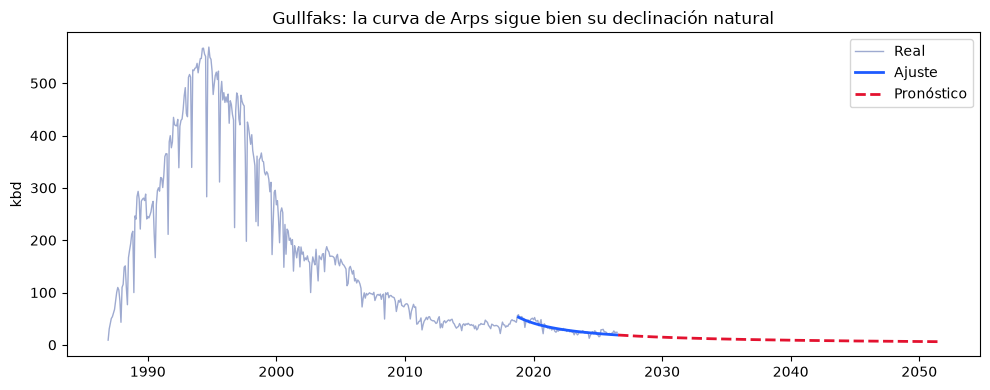

Petróleo remanente según la curva: 92.9 MMbbl | según Sodir: 67.0 MMbbl


In [7]:
def ajustar_campo(nombre):
    g = prod[prod['campo'] == nombre]
    tramo = P.ventana_declinacion(g)
    if tramo is None:
        return None
    t = (tramo['fecha'] - tramo['fecha'].iloc[0]).dt.days / 365.25
    a = P.ajustar_arps(t, tramo['petroleo_kbd'])
    q = P.pronostico(a, t.iloc[-1])
    return tramo, t, a, q

tramo, t, a, q = ajustar_campo('GULLFAKS')
print({k: round(v, 3) for k, v in a.items()}, '| calidad:', P.calidad(a['r2']))
fechas = pd.date_range(tramo['fecha'].iloc[-1], periods=len(q) + 1, freq='MS')[1:]
g = prod[prod['campo'] == 'GULLFAKS']
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(g['fecha'], g['petroleo_kbd'], color='#9EAAD0', lw=1, label='Real')
ax.plot(tramo['fecha'], P.arps(t, a['qi'], a['di'], a['b']), color='#1E5BFF', lw=2, label='Ajuste')
ax.plot(fechas, q, color='#E3122F', lw=2, ls='--', label='Pronóstico')
ax.set_ylabel('kbd'); ax.legend(); ax.set_title('Gullfaks: la curva de Arps sigue bien su declinación natural')
plt.tight_layout(); plt.savefig('graficos/declinacion_gullfaks.png', dpi=120); plt.show()
print(f'Petróleo remanente según la curva: {q.sum() * 30.4375 / 1000:.1f} MMbbl | según Sodir: '
      f'{reservas.set_index("campo").loc["GULLFAKS", "remanente_mmbbl"]:.1f} MMbbl')

### ¿Qué tan confiable es la curva en cada campo?
Se compara el remanente de la curva con la reserva oficial. Una diferencia grande no siempre es un error: la reserva oficial incluye pozos y proyectos nuevos que la curva no ve.

In [8]:
filas = []
for nombre in hoy[hoy >= 5].index:
    r = ajustar_campo(nombre)
    if r is None:
        filas.append({'campo': nombre, 'calidad': 'meseta: aún no aplica'}); continue
    _, _, ak, qk = r
    filas.append({'campo': nombre, 'di': ak['di'], 'b': ak['b'], 'r2': ak['r2'], 'calidad': P.calidad(ak['r2']),
                  'rem_curva': qk.sum() * 30.4375 / 1000})
dca = pd.DataFrame(filas).merge(reservas[['campo', 'remanente_mmbbl']], on='campo', how='left')
print(dca['calidad'].value_counts())
buenos = dca[dca['calidad'] == 'confiable']
dif = (buenos['rem_curva'] / buenos['remanente_mmbbl'] - 1).abs().median()
print(f'En los campos con ajuste confiable, la diferencia mediana con la reserva oficial es {dif:.0%}')
dca.round(2).sort_values('r2', ascending=False)

calidad
poco confiable           17
meseta: aún no aplica    13
confiable                12
moderado                 11
Name: count, dtype: int64
En los campos con ajuste confiable, la diferencia mediana con la reserva oficial es 79%


,campo,calidad,di,b,r2,rem_curva,remanente_mmbbl
17,TROLL,confiable,0.20,0.00,0.89,38.48,20.76
41,TYRIHANS,confiable,0.31,0.95,0.85,37.08,11.13
51,STATFJORD ØST,confiable,0.64,1.00,0.82,11.77,12.33
42,FENJA,confiable,0.64,0.00,0.82,2.73,19.75
13,EDVARD GRIEG,confiable,0.40,0.00,0.76,15.00,70.01
48,GINA KROG,confiable,0.64,0.75,0.76,21.04,6.29
52,KVITEBJØRN,confiable,0.37,0.70,0.76,20.56,7.86
14,GULLFAKS,confiable,0.23,1.00,0.73,92.93,66.99
38,GUDRUN,confiable,0.19,0.00,0.69,16.13,21.39
29,IVAR AASEN,confiable,0.27,0.15,0.64,21.37,37.99


## 8. ¿Cuánto vale la producción futura?
Valor presente neto (VPN) del pronóstico de Gullfaks: flujo = barriles × (Brent − costo operativo) × (1 − impuesto). Impuesto 78 % (régimen petrolero noruego: 22 % general + 56 % especial), costo operativo 15 USD/bbl y tasa de descuento 10 %. **Es una estimación simplificada con fines de aprendizaje:** no incluye inversiones, gas ni costos de abandono.

In [9]:
escenarios = pd.DataFrame([
    {'escenario': nombre, 'brent': precio, 'vpn_musd': P.vpn(q, precio, opex=15, impuesto=.78, tasa=.10)}
    for nombre, precio in [('Bajo', 55), ('Base (12 meses)', round(brent.tail(12)['brent'].mean())), ('Alto', 95)]])
escenarios['vpn_musd'] = escenarios['vpn_musd'].round(0)
escenarios

,escenario,brent,vpn_musd
0,Bajo,55,378.0
1,Base (12 meses),78,596.0
2,Alto,95,756.0


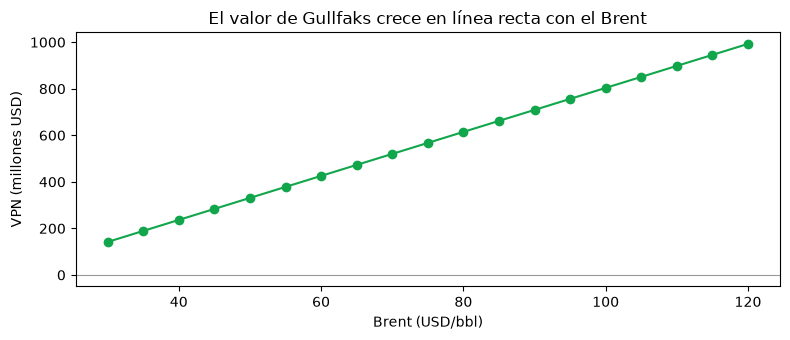

In [10]:
precios = np.arange(30, 121, 5)
ax = pd.Series([P.vpn(q, p, 15, .78, .10) for p in precios], index=precios).plot(
    marker='o', color='#11A64B', figsize=(8, 3.5), title='El valor de Gullfaks crece en línea recta con el Brent')
ax.set_xlabel('Brent (USD/bbl)'); ax.set_ylabel('VPN (millones USD)'); ax.axhline(0, color='#999', lw=.8)
plt.tight_layout(); plt.savefig('graficos/vpn_gullfaks.png', dpi=120); plt.show()

## 9. Conclusiones
Los números exactos están en las celdas de arriba y se recalculan al actualizar los datos.

1. **Cuenca madura que se reinventa:** la producción tocó techo en 2001, cayó a más de la mitad en 2019 y se recuperó con campos nuevos como Johan Sverdrup y Johan Castberg.
2. **Riesgo concentrado:** dos campos aportan casi la mitad del petróleo; una falla en uno de ellos mueve la producción del país.
3. **Más agua que petróleo:** el corte de agua pasa del 60 %, así que manejar el agua es parte central del costo.
4. **La curva de declinación sirve, con criterio:** funciona bien en campos que declinan de forma natural, pero no en los que siguen en meseta o reciben pozos nuevos. Incluso en los ajustes confiables la diferencia con la reserva oficial es grande, porque la curva no sabe cuándo el operador cerrará el campo: el **límite económico** pesa tanto como el ajuste.
5. **El valor depende del precio:** con la misma producción, el VPN cambia en proporción al Brent menos el costo operativo.

**Limitaciones:** solo se evalúa el petróleo (no el gas); el modelo económico no incluye inversiones; la curva no prevé perforaciones nuevas ni proyectos de recuperación mejorada.